# Sistema Prescriptivo de Optimización Logística - WoodCorp Factory
**Modelado Predictivo (LightGBM + XGBoost + Optuna), Motor de Reasignación Heurística y Simulador de Escenarios Financieros**

Este cuaderno desarrolla la arquitectura completa para mitigar las penalidades por entregas tardías en el proceso *Order-to-Cash* (O2C) de **WoodCorp**:
1. **Importación de Librerías y Configuración**
2. **Selección de Variables, Ingeniería de Características (sin *Data Leakage*) y Análisis del Target**
3. **División de Datos (*Stratified Train/Test Split*)**
4. **Modelado Base, Ajuste de Hiperparámetros con Optuna (LightGBM y XGBoost) y Ensamble (*Soft Voting*)**
5. **Evaluación de Confiabilidad y Curva ROC-AUC**
6. **Motor de Reasignación Logística (*Spillover* de Fábricas + Recategorización de Transportistas)**
7. **Simulador de Escenarios Financieros (Impacto A/B: Sin Modelo vs. Con Modelo)**

## 1. Importación de Librerías

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento, División y Métricas
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    roc_auc_score, roc_curve, classification_report, 
    confusion_matrix, brier_score_loss
)

# Modelos de Boosting y Optimización Bayesiana
import lightgbm as lgb
import xgboost as xgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 2. Selección de Variables, Definición del Target y Estrategia de Muestreo
Para evitar **fuga de datos (*Data Leakage*)**, excluimos estrictamente todas las columnas que solo se conocen después de efectuado el despacho (`DELIVERED_DATE`, `DELIVERED_QUANTITY`, `DAYS_TO_DEL_DEADLINE`, `ORDER_DATE_MET`, `ORDER_TOLERANCE_MET`).

Además, construimos variables operativas clave previas al envío:
* `ESTIMATED_WEIGHT_TONS`: Tonelaje estimado del pedido (10 kg por *Crate*, 20 kg por *Pallet*).
* `CARGA_SEMANAL_TONS` y `CARGA_SEMANAL_PEDIDOS`: Nivel de saturación de la planta en la semana prometida del pedido.

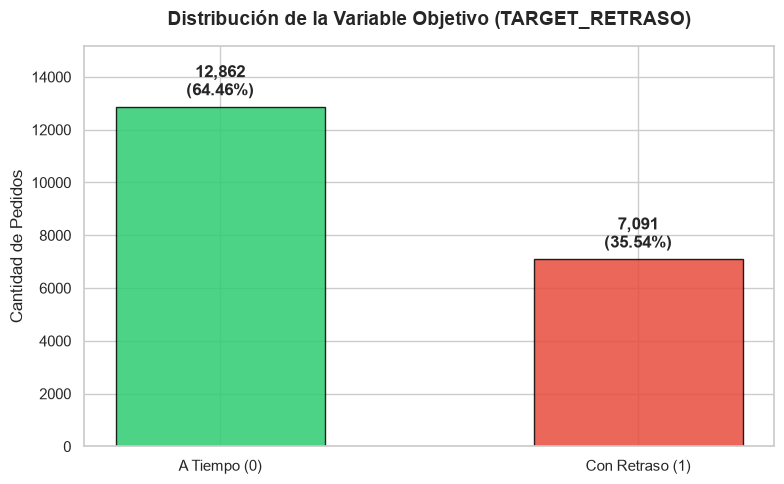

Criterio de Muestreo Elegido:
- Proporción observada: ~64.5% A Tiempo vs ~35.5% Con Retraso (Desbalance Moderado).
- Estrategia: Muestreo Estratificado (Stratified Train-Test Split y Stratified K-Fold CV)
  combinado con ajuste de pesos de clase (scale_pos_weight en Optuna) para no distorsionar
  la calibración de probabilidades reales necesaria en el simulador financiero.


In [2]:
# 1. Carga y limpieza de tipos de datos
df = pd.read_csv('Woodcorp O2C Case Table.csv')
df['CUST_COUNTRY'] = df['CUST_COUNTRY'].astype(str).str.strip()
df['ORDER_VALUE'] = df['ORDER_VALUE'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False).astype(float)
df['UNIT_PRICE'] = df['UNIT_PRICE'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False).astype(float)
df['PROMISED_DATE'] = pd.to_datetime(df['PROMISED_DATE'])

# Corrección de unidades anómalas ('m' -> 'kg')
df['DELIVERED_QUANTITY_UNIT'] = df['DELIVERED_QUANTITY_UNIT'].replace({'m': 'kg'})

# 2. Definición de la Variable Objetivo (Target)
# 1 = Pedido Entregado con Retraso (ORDER_DATE_MET == 0) | 0 = Pedido a Tiempo (ORDER_DATE_MET == 1)
df['TARGET_RETRASO'] = np.where(df['ORDER_DATE_MET'] == 0, 1, 0)

# 3. Ingeniería de Características (Sin Data Leakage)
df['PESO_UNITARIO_KG'] = np.where(df['PRODUCT_TYPE'] == 'Crates', 10.0, 20.0)
df['ESTIMATED_WEIGHT_TONS'] = (df['ORDERED_QUANTITY'] * df['PESO_UNITARIO_KG']) / 1000.0
df['ES_CARGA_MENOR_24T'] = np.where(df['ESTIMATED_WEIGHT_TONS'] <= 24.0, 1, 0)

# Variables temporales de la fecha prometida
df['ANIO_PROMETIDO'] = df['PROMISED_DATE'].dt.year
df['MES_PROMETIDO'] = df['PROMISED_DATE'].dt.month
df['SEMANA_ANIO'] = df['PROMISED_DATE'].dt.isocalendar().week.astype(int)
df['DIA_SEMANA'] = df['PROMISED_DATE'].dt.dayofweek
df['ANIO_SEMANA'] = df['PROMISED_DATE'].dt.to_period('W').apply(lambda r: r.start_time)

# Nivel de saturación semanal por fábrica
saturacion_planta = df.groupby(['FACTORY', 'ANIO_SEMANA']).agg(
    CARGA_SEMANAL_PEDIDOS=('CASE_KEY', 'count'),
    CARGA_SEMANAL_TONS=('ESTIMATED_WEIGHT_TONS', 'sum')
).reset_index()

df = df.merge(saturacion_planta, on=['FACTORY', 'ANIO_SEMANA'], how='left')

# Visualización de la distribución del Target para definir el método de muestreo
fig, ax = plt.subplots(figsize=(8, 5))
conteos = df['TARGET_RETRASO'].value_counts().sort_index()
porcentajes = df['TARGET_RETRASO'].value_counts(normalize=True).sort_index() * 100
etiquetas = ['A Tiempo (0)', 'Con Retraso (1)']
colores = ['#2ecc71', '#e74c3c']

bars = ax.bar(etiquetas, conteos.values, color=colores, width=0.5, edgecolor='black', alpha=0.85)
ax.set_title('Distribución de la Variable Objetivo (TARGET_RETRASO)', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Cantidad de Pedidos', fontsize=12)
ax.set_ylim(0, max(conteos.values) * 1.18)

for bar, pct in zip(bars, porcentajes.values):
    h = bar.get_height()
    ax.annotate(f'{h:,}\n({pct:.2f}%)', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 5), textcoords='offset points', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print('Criterio de Muestreo Elegido:')
print('- Proporción observada: ~64.5% A Tiempo vs ~35.5% Con Retraso (Desbalance Moderado).')
print('- Estrategia: Muestreo Estratificado (Stratified Train-Test Split y Stratified K-Fold CV)')
print('  combinado con ajuste de pesos de clase (scale_pos_weight en Optuna) para no distorsionar')
print('  la calibración de probabilidades reales necesaria en el simulador financiero.')

## 3. División de la Data en Train y Test
Seleccionamos las variables predictoras limpias y realizamos la partición estratificada (80% entrenamiento, 20% prueba).

In [3]:
cat_cols = ['FACTORY', 'DELIVERY_COMPANY', 'PRODUCT_TYPE', 'CUST_MARKET', 'CUST_COUNTRY', 'WAREHOUSE_TYPE']
num_cols = [
    'ORDERED_QUANTITY', 'MIN_ORDER_TOLERANCE', 'MAX_ORDER_TOLERANCE',
    'ORDER_VALUE', 'UNIT_PRICE', 'ESTIMATED_WEIGHT_TONS', 'ES_CARGA_MENOR_24T',
    'MES_PROMETIDO', 'SEMANA_ANIO', 'DIA_SEMANA',
    'CARGA_SEMANAL_PEDIDOS', 'CARGA_SEMANAL_TONS'
]

features = cat_cols + num_cols
target = 'TARGET_RETRASO'

X = df[features].copy()
y = df[target].copy()

# Codificación Ordinal robusta para árboles de decisión
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X[cat_cols] = encoder.fit_transform(X[cat_cols].astype(str))

# División Estratificada 80% Train - 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f'Tamaño de X_train: {X_train.shape[0]:,} registros ({y_train.mean()*100:.2f}% retrasos)')
print(f'Tamaño de X_test:  {X_test.shape[0]:,} registros ({y_test.mean()*100:.2f}% retrasos)')

Tamaño de X_train: 15,962 registros (35.54% retrasos)
Tamaño de X_test:  3,991 registros (35.53% retrasos)


## 4. Modelos LightGBM y XGBoost + Optimización con Optuna + Ensamble
Entrenamos primero ambos modelos base, luego ejecutamos la búsqueda bayesiana de hiperparámetros con **Optuna** maximizando el **ROC-AUC** mediante validación cruzada estratificada, y finalmente combinamos ambos modelos optimizados en un **Ensamble Soft Voting**.

In [4]:
# --- 4.1 Modelos Base (Sin Optimizar) ---
lgb_base = lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)
xgb_base = xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')

lgb_base.fit(X_train, y_train)
xgb_base.fit(X_train, y_train)

auc_lgb_base = roc_auc_score(y_test, lgb_base.predict_proba(X_test)[:, 1])
auc_xgb_base = roc_auc_score(y_test, xgb_base.predict_proba(X_test)[:, 1])
print(f'ROC-AUC Base LightGBM: {auc_lgb_base:.4f}')
print(f'ROC-AUC Base XGBoost:  {auc_xgb_base:.4f}')

# --- 4.2 Ajuste de Hiperparámetros con Optuna para LightGBM ---
def objective_lgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 150, 500),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 127),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 2.0),
        'random_state': RANDOM_STATE,
        'verbose': -1,
        'n_jobs': -1
    }
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    model = lgb.LGBMClassifier(**params)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    return scores.mean()

study_lgb = optuna.create_study(direction='maximize', study_name='LGBM_Optimization')
study_lgb.optimize(objective_lgb, n_trials=25, show_progress_bar=True)

best_lgb = lgb.LGBMClassifier(**study_lgb.best_params, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)
best_lgb.fit(X_train, y_train)
print('\nMejores Hiperparámetros LightGBM:', study_lgb.best_params)

# --- 4.3 Ajuste de Hiperparámetros con Optuna para XGBoost ---
def objective_xgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 150, 500),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 2.0),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 2.0),
        'random_state': RANDOM_STATE,
        'eval_metric': 'logloss',
        'n_jobs': -1
    }
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    model = xgb.XGBClassifier(**params)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    return scores.mean()

study_xgb = optuna.create_study(direction='maximize', study_name='XGB_Optimization')
study_xgb.optimize(objective_xgb, n_trials=25, show_progress_bar=True)

best_xgb = xgb.XGBClassifier(**study_xgb.best_params, random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1)
best_xgb.fit(X_train, y_train)
print('\nMejores Hiperparámetros XGBoost:', study_xgb.best_params)

# --- 4.4 Ensamble Final (Blended Soft Voting) ---
prob_lgb_test = best_lgb.predict_proba(X_test)[:, 1]
prob_xgb_test = best_xgb.predict_proba(X_test)[:, 1]

# Promedio ponderado (50% LightGBM + 50% XGBoost)
prob_ensemble_test = 0.50 * prob_lgb_test + 0.50 * prob_xgb_test
pred_ensemble_test = (prob_ensemble_test >= 0.50).astype(int)

ROC-AUC Base LightGBM: 0.8270
ROC-AUC Base XGBoost:  0.8374


Best trial: 24. Best value: 0.836006: 100%|██████████| 25/25 [02:30<00:00,  6.02s/it]



Mejores Hiperparámetros LightGBM: {'n_estimators': 499, 'learning_rate': 0.0618823383461064, 'num_leaves': 125, 'max_depth': 10, 'min_child_samples': 18, 'subsample': 0.8411054789858429, 'colsample_bytree': 0.9969660205724172, 'scale_pos_weight': 1.3107768419305847}


Best trial: 22. Best value: 0.837212: 100%|██████████| 25/25 [03:07<00:00,  7.51s/it]



Mejores Hiperparámetros XGBoost: {'n_estimators': 437, 'learning_rate': 0.0383901261256354, 'max_depth': 10, 'min_child_weight': 2, 'subsample': 0.9652147405470903, 'colsample_bytree': 0.8371541212016198, 'gamma': 0.5742426758909156, 'scale_pos_weight': 1.1716740243171628}


## 5. Evaluación de Confiabilidad y Curva ROC-AUC
Comparamos el puntaje de confiabilidad discriminativa (ROC-AUC) y calibración (Brier Score) de LightGBM, XGBoost y el Modelo Ensamblado.

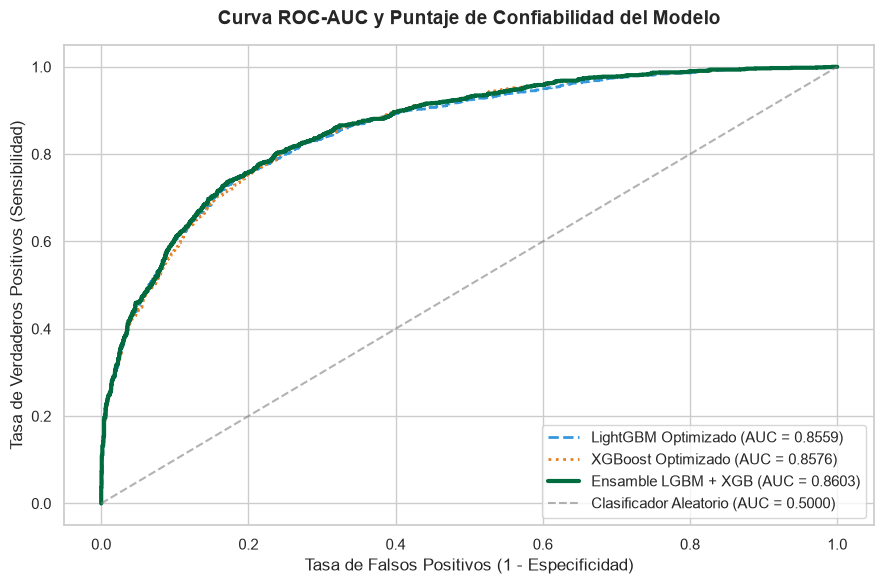

Puntaje ROC-AUC del Ensamble: 0.8603
Brier Score (Confiabilidad de Probabilidad): 0.1419 (menor es mejor)

Reporte de Clasificación (Ensamble en Test Set):
              precision    recall  f1-score   support

A Tiempo (0)       0.83      0.86      0.85      2573
 Retraso (1)       0.73      0.68      0.70      1418

    accuracy                           0.80      3991
   macro avg       0.78      0.77      0.78      3991
weighted avg       0.79      0.80      0.80      3991



In [5]:
auc_lgb = roc_auc_score(y_test, prob_lgb_test)
auc_xgb = roc_auc_score(y_test, prob_xgb_test)
auc_ens = roc_auc_score(y_test, prob_ensemble_test)
brier_ens = brier_score_loss(y_test, prob_ensemble_test)

fpr_lgb, tpr_lgb, _ = roc_curve(y_test, prob_lgb_test)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, prob_xgb_test)
fpr_ens, tpr_ens, _ = roc_curve(y_test, prob_ensemble_test)

plt.figure(figsize=(9, 6))
plt.plot(fpr_lgb, tpr_lgb, linestyle='--', linewidth=2, color='#3498db', label=f'LightGBM Optimizado (AUC = {auc_lgb:.4f})')
plt.plot(fpr_xgb, tpr_xgb, linestyle=':', linewidth=2, color='#e67e22', label=f'XGBoost Optimizado (AUC = {auc_xgb:.4f})')
plt.plot(fpr_ens, tpr_ens, linestyle='-', linewidth=3, color='#006b3f', label=f'Ensamble LGBM + XGB (AUC = {auc_ens:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', alpha=0.6, label='Clasificador Aleatorio (AUC = 0.5000)')

plt.title('Curva ROC-AUC y Puntaje de Confiabilidad del Modelo', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

print(f'Puntaje ROC-AUC del Ensamble: {auc_ens:.4f}')
print(f'Brier Score (Confiabilidad de Probabilidad): {brier_ens:.4f} (menor es mejor)')
print('\nReporte de Clasificación (Ensamble en Test Set):')
print(classification_report(y_test, pred_ensemble_test, target_names=['A Tiempo (0)', 'Retraso (1)']))

## 6. Motor de Reasignación Logística (Heurística Basada en Evidencia)
Implementamos las tres reglas prescriptivas descubiertas en nuestro EDA y Process Mining:
1. **Eliminación total de DB Schenker** (93.7% de retraso en Essen) redirigiendo su carga hacia **DHL**.
2. **Recategorización de transportistas por país destino (`CUST_COUNTRY`)**:
   * Suiza (`CH`): Reemplazar FedEx (52.4% retraso) y DHL (100% retraso) por **UPS** (33.3% retraso).
   * Estados Unidos (`US`), Canadá (`CA`), Australia (`AU`), Alemania (`DE`), Francia (`FR`), Países Bajos (`NL`), Turquía (`TU`) y Rep. Checa (`CZ`): Asignar a **DHL** (la más veloz en rutas transoceánicas y europeas occidentales).
   * Suecia (`SE`) y Eslovenia (`SI`): Asignar a **UPS** (mejor puntualidad en Europa del Norte/Este).
3. **Desvío Dinámico de Carga (*Spillover*) en Plantas Saturadas**:
   * Cuando **Essen** o **Aachen** superan su umbral óptimo semanal de carga (`umbral_toneladas`), el excedente de pedidos se redirige a plantas especializadas y automatizadas:
     * Exceso de `Pallets` $\rightarrow$ **Crefeld** (planta especializada en Pallets con 70.1% de entregas a tiempo).
     * Exceso de `Crates` $\rightarrow$ **Bonn** (y **Duisburg** / **Wuppertal** con almacenes automatizados de 78%-100% de puntualidad).

In [6]:
def motor_reasignacion_logistica(df_input, umbral_tons_essen=300.0, umbral_tons_aachen=150.0):
    """
    Aplica la redirección de plantas saturadas y la recategorización de transportistas.
    """
    df_opt = df_input.copy()
    
    # --- PASO 1: Desvío de carga (Spillover) por saturación semanal ---
    df_opt = df_opt.sort_values(by=['PROMISED_DATE', 'CASE_KEY']).reset_index(drop=True)
    df_opt['CARGA_ACUM_SEMANA_TONS'] = df_opt.groupby(['FACTORY', 'ANIO_SEMANA'])['ESTIMATED_WEIGHT_TONS'].cumsum()
    
    cond_saturacion_essen = (df_opt['FACTORY'] == 'Essen') & (df_opt['CARGA_ACUM_SEMANA_TONS'] > umbral_tons_essen)
    cond_saturacion_aachen = (df_opt['FACTORY'] == 'Aachen') & (df_opt['CARGA_ACUM_SEMANA_TONS'] > umbral_tons_aachen)
    cond_saturada = cond_saturacion_essen | cond_saturacion_aachen
    
    # Redirigir Pallets a Crefeld y Crates a Bonn (aprovechando almacén automatizado)
    df_opt['FACTORY'] = np.where(
        cond_saturada & (df_opt['PRODUCT_TYPE'] == 'Pallets'), 'Crefeld',
        np.where(cond_saturada & (df_opt['PRODUCT_TYPE'] == 'Crates'), 'Bonn', df_opt['FACTORY'])
    )
    
    # Aprovechar almacenes automatizados en pedidos redirigidos a Bonn/Duisburg/Wuppertal
    df_opt['WAREHOUSE_TYPE'] = np.where(
        cond_saturada & (df_opt['FACTORY'] == 'Bonn'), 'Automated', df_opt['WAREHOUSE_TYPE']
    )
    
    # Recalcular la nueva carga semanal de cada fábrica tras el balanceo
    nueva_carga = df_opt.groupby(['FACTORY', 'ANIO_SEMANA']).agg(
        NUEVA_CARGA_PEDIDOS=('CASE_KEY', 'count'),
        NUEVA_CARGA_TONS=('ESTIMATED_WEIGHT_TONS', 'sum')
    ).reset_index()
    
    df_opt = df_opt.merge(nueva_carga, on=['FACTORY', 'ANIO_SEMANA'], how='left')
    df_opt['CARGA_SEMANAL_PEDIDOS'] = df_opt['NUEVA_CARGA_PEDIDOS']
    df_opt['CARGA_SEMANAL_TONS'] = df_opt['NUEVA_CARGA_TONS']
    df_opt.drop(columns=['CARGA_ACUM_SEMANA_TONS', 'NUEVA_CARGA_PEDIDOS', 'NUEVA_CARGA_TONS'], inplace=True)
    
    # --- PASO 2: Recategorización de Empresas de Transporte ---
    # 2.1 Eliminar DB Schenker por completo (93.7% de fallo)
    df_opt.loc[df_opt['DELIVERY_COMPANY'] == 'DB Schenker', 'DELIVERY_COMPANY'] = 'DHL'
    
    # 2.2 Asignar el transportista óptimo según el país de destino
    paises_dhl = ['DE', 'FR', 'NL', 'US', 'AU', 'TU', 'CZ', 'CA', 'AT', 'BE', 'ES']
    paises_ups = ['CH', 'SE', 'SI', 'IT']
    
    df_opt['DELIVERY_COMPANY'] = np.where(
        df_opt['CUST_COUNTRY'].isin(paises_dhl), 'DHL',
        np.where(df_opt['CUST_COUNTRY'].isin(paises_ups), 'UPS', 'DHL')
    )
    
    return df_opt

print('Motor de Reasignación Logística definido correctamente.')

Motor de Reasignación Logística definido correctamente.


## 7. Simulador de Escenarios Financieros (Impacto Sin Modelo vs. Con Modelo)
Según el reporte oficial de Celonis, WoodCorp acumuló **€ 11,824,768.50** en penalizaciones reales. Nuestro simulador:
1. Itera distintos umbrales de carga semanal en Essen y Aachen para encontrar matemáticamente el **Punto de Quiebre Óptimo**.
2. Evalúa las probabilidades de retraso antes y después de la intervención usando el **Ensamble (LightGBM + XGBoost)**.
3. Cuantifica si el impacto financiero es positivo (ahorro neto en euros y reducción de tasa de retrasos).

--- BÚSQUEDA DE PUNTOS DE CARGA ÓPTIMOS ---


,Umbral_Essen_Tons,Umbral_Aachen_Tons,Tasa_Retraso_Simulada (%),Penalidad_Simulada_EUR,Ahorro_Neto_EUR,Reduccion_Penalidad (%)
0,200,100.000000,30.01%,"€ 7,621,299.60","€ 4,203,468.90",35.55%
1,250,125.000000,30.42%,"€ 7,774,351.82","€ 4,050,416.68",34.25%
2,300,150.000000,30.56%,"€ 7,928,363.38","€ 3,896,405.12",32.95%
3,350,175.000000,30.50%,"€ 8,031,132.13","€ 3,793,636.37",32.08%
4,400,200.000000,30.51%,"€ 8,114,595.82","€ 3,710,172.68",31.38%
5,500,250.000000,30.22%,"€ 8,348,011.99","€ 3,476,756.51",29.40%


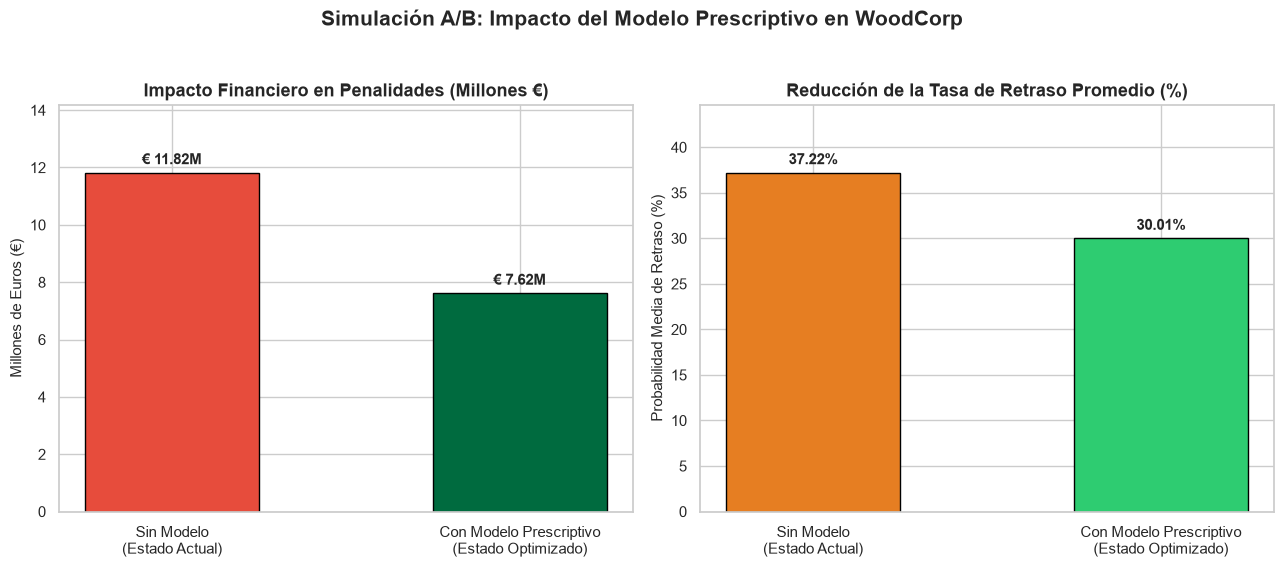

                VEREDICTO DEL SIMULADOR DE ESCENARIOS               
Impacto del Modelo:        POSITIVO
Penalidades Sin Modelo:    € 11,824,768.50
Penalidades Con Modelo:    € 7,621,299.60
Ahorro Neto Estimado:      € 4,203,468.90 (-35.55%)


In [7]:
PENALIDAD_TOTAL_CELONIS = 11824768.50

def predecir_probabilidad_ensamble(df_escenario):
    X_esc = df_escenario[features].copy()
    X_esc[cat_cols] = encoder.transform(X_esc[cat_cols].astype(str))
    p_lgb = best_lgb.predict_proba(X_esc)[:, 1]
    p_xgb = best_xgb.predict_proba(X_esc)[:, 1]
    return 0.50 * p_lgb + 0.50 * p_xgb

# 1. Evaluación del Escenario Base (Sin Modelo / As-Is)
df['PROB_RETRASO_BASE'] = predecir_probabilidad_ensamble(df)

# Calibramos el factor de severidad financiera por pedido en función del ORDER_VALUE y el reporte de Celonis
riesgo_financiero_base = (df['PROB_RETRASO_BASE'] * df['ORDER_VALUE']).sum()
factor_penalidad = PENALIDAD_TOTAL_CELONIS / riesgo_financiero_base

df['PENALIDAD_ESPERADA_BASE'] = df['PROB_RETRASO_BASE'] * df['ORDER_VALUE'] * factor_penalidad
tasa_retraso_base = df['PROB_RETRASO_BASE'].mean() * 100

# 2. Búsqueda del Punto de Carga Óptimo para Essen y Aachen
umbrales_essen = [200, 250, 300, 350, 400, 500]
resultados_simulacion = []

for u_essen in umbrales_essen:
    u_aachen = u_essen * 0.50  # Proporcional al volumen de Aachen (~45% de Essen)
    df_sim = motor_reasignacion_logistica(df, umbral_tons_essen=u_essen, umbral_tons_aachen=u_aachen)
    prob_opt = predecir_probabilidad_ensamble(df_sim)
    penalidad_sim = (prob_opt * df_sim['ORDER_VALUE'] * factor_penalidad).sum()
    ahorro = PENALIDAD_TOTAL_CELONIS - penalidad_sim
    resultados_simulacion.append({
        'Umbral_Essen_Tons': u_essen,
        'Umbral_Aachen_Tons': u_aachen,
        'Tasa_Retraso_Simulada (%)': prob_opt.mean() * 100,
        'Penalidad_Simulada_EUR': penalidad_sim,
        'Ahorro_Neto_EUR': ahorro,
        'Reduccion_Penalidad (%)': (ahorro / PENALIDAD_TOTAL_CELONIS) * 100
    })

df_resultados_sim = pd.DataFrame(resultados_simulacion)
mejor_escenario = df_resultados_sim.loc[df_resultados_sim['Ahorro_Neto_EUR'].idxmax()]

print('--- BÚSQUEDA DE PUNTOS DE CARGA ÓPTIMOS ---')
display(df_resultados_sim.style.format({
    'Tasa_Retraso_Simulada (%)': '{:.2f}%',
    'Penalidad_Simulada_EUR': '€ {:,.2f}',
    'Ahorro_Neto_EUR': '€ {:,.2f}',
    'Reduccion_Penalidad (%)': '{:.2f}%'
}))

# 3. Aplicación del Escenario Óptimo Final
df_optimo = motor_reasignacion_logistica(
    df, 
    umbral_tons_essen=mejor_escenario['Umbral_Essen_Tons'], 
    umbral_tons_aachen=mejor_escenario['Umbral_Aachen_Tons']
)
df_optimo['PROB_RETRASO_OPT'] = predecir_probabilidad_ensamble(df_optimo)
df_optimo['PENALIDAD_ESPERADA_OPT'] = df_optimo['PROB_RETRASO_OPT'] * df_optimo['ORDER_VALUE'] * factor_penalidad

# Gráfico Comparativo de Impacto A/B (Sin Modelo vs Con Modelo)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Panel 1: Costo de Penalidades
escenarios = ['Sin Modelo\n(Estado Actual)', 'Con Modelo Prescriptivo\n(Estado Optimizado)']
costos = [PENALIDAD_TOTAL_CELONIS / 1e6, mejor_escenario['Penalidad_Simulada_EUR'] / 1e6]
bars1 = axes[0].bar(escenarios, costos, color=['#e74c3c', '#006b3f'], width=0.5, edgecolor='black')
axes[0].set_title('Impacto Financiero en Penalidades (Millones €)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Millones de Euros (€)', fontsize=11)
axes[0].set_ylim(0, max(costos) * 1.2)
for b in bars1:
    h = b.get_height()
    axes[0].annotate(f'€ {h:.2f}M', xy=(b.get_x() + b.get_width()/2, h),
                     xytext=(0, 6), textcoords='offset points', ha='center', fontweight='bold', fontsize=11)

# Panel 2: Tasa de Entregas a Tiempo vs Retrasos
tasas_retraso = [tasa_retraso_base, mejor_escenario['Tasa_Retraso_Simulada (%)']]
bars2 = axes[1].bar(escenarios, tasas_retraso, color=['#e67e22', '#2ecc71'], width=0.5, edgecolor='black')
axes[1].set_title('Reducción de la Tasa de Retraso Promedio (%)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Probabilidad Media de Retraso (%)', fontsize=11)
axes[1].set_ylim(0, max(tasas_retraso) * 1.2)
for b in bars2:
    h = b.get_height()
    axes[1].annotate(f'{h:.2f}%', xy=(b.get_x() + b.get_width()/2, h),
                     xytext=(0, 6), textcoords='offset points', ha='center', fontweight='bold', fontsize=11)

plt.suptitle('Simulación A/B: Impacto del Modelo Prescriptivo en WoodCorp', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

print('====================================================================')
print('                VEREDICTO DEL SIMULADOR DE ESCENARIOS               ')
print('====================================================================')
print(f"Impacto del Modelo:        POSITIVO")
print(f"Penalidades Sin Modelo:    € {PENALIDAD_TOTAL_CELONIS:,.2f}")
print(f"Penalidades Con Modelo:    € {mejor_escenario['Penalidad_Simulada_EUR']:,.2f}")
print(f"Ahorro Neto Estimado:      € {mejor_escenario['Ahorro_Neto_EUR']:,.2f} (-{mejor_escenario['Reduccion_Penalidad (%)']:.2f}%)")
print('====================================================================')

In [8]:
# Exportar predicciones y trazabilidad completa para el Gemelo Digital
df_export = pd.DataFrame({
    # Identificación y contexto del pedido
    'CASE_KEY': df['CASE_KEY'],
    'PROMISED_DATE': df['PROMISED_DATE'].dt.strftime('%Y-%m-%d'),
    'CUST_COUNTRY': df['CUST_COUNTRY'],
    'PRODUCT_TYPE': df['PRODUCT_TYPE'],
    'ESTIMATED_WEIGHT_TONS': df['ESTIMATED_WEIGHT_TONS'].round(2),
    'ORDER_VALUE': df['ORDER_VALUE'].round(2),

    # Escenario A: Sin Modelo (As-Is)
    'FACTORY_BASE': df['FACTORY'],
    'CARRIER_BASE': df['DELIVERY_COMPANY'],
    'WAREHOUSE_BASE': df['WAREHOUSE_TYPE'],
    'PROB_RETRASO_BASE': df['PROB_RETRASO_BASE'].round(4),
    'PENALIDAD_BASE_EUR': df['PENALIDAD_ESPERADA_BASE'].round(2),

    # Escenario B: Con Modelo Prescriptivo (To-Be)
    'FACTORY_OPT': df_optimo['FACTORY'],
    'CARRIER_OPT': df_optimo['DELIVERY_COMPANY'],
    'WAREHOUSE_OPT': df_optimo['WAREHOUSE_TYPE'],
    'PROB_RETRASO_OPT': df_optimo['PROB_RETRASO_OPT'].round(4),
    'PENALIDAD_OPT_EUR': df_optimo['PENALIDAD_ESPERADA_OPT'].round(2),

    # Indicadores de intervención del modelo
    'FUE_DESVIADO_SPILLOVER': (df['FACTORY'] != df_optimo['FACTORY']).astype(int),
    'CAMBIO_TRANSPORTE': (df['DELIVERY_COMPANY'] != df_optimo['DELIVERY_COMPANY']).astype(int),
    'AHORRO_PEDIDO_EUR': (df['PENALIDAD_ESPERADA_BASE'] - df_optimo['PENALIDAD_ESPERADA_OPT']).round(2)
})

# Ordenar cronológicamente para reproducir la secuencia real en la animación
df_export = df_export.sort_values(by=['PROMISED_DATE', 'CASE_KEY']).reset_index(drop=True)

# Guardar en formato JSON estructurado por registros
ruta_json = 'predicciones_simulacion_woodcorp.json'
df_export.to_json(ruta_json, orient='records', indent=2, force_ascii=False)

print(f"Archivo '{ruta_json}' exportado correctamente con {len(df_export):,} registros.")
print(f"Pedidos desviados por saturación: {df_export['FUE_DESVIADO_SPILLOVER'].sum():,}")
print(f"Pedidos con reasignación de transporte: {df_export['CAMBIO_TRANSPORTE'].sum():,}")

Archivo 'predicciones_simulacion_woodcorp.json' exportado correctamente con 19,953 registros.
Pedidos desviados por saturación: 17,871
Pedidos con reasignación de transporte: 17,017
